In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rfm = pd.read_parquet("../data/rfm.parquet")
print(f"Učitano {len(rfm):,} kupaca.")
rfm.head()

Učitano 5,852 kupaca.


,CustomerID,Recency,Frequency,Monetary,R,F,M,Segment
0,12346,326,3,77352.96,2,3,5,U riziku
1,12347,2,8,4921.53,5,4,5,Šampioni
2,12348,75,5,1658.40,3,4,4,Lojalni
3,12349,19,3,3678.69,4,3,5,Potencijalno lojalni
4,12350,310,1,294.40,2,1,2,Izgubljeni


# 4.1 Priprema podataka

In [2]:
x = rfm[["Recency", "Frequency", "Monetary"]]
print("Asimetrija (skew) PRIJE log transformacije:")
print(x.skew().round(2).to_dict())

x_log = np.log1p(x)
print("\nAsimetrija (skew) POSLIJE log transformacije:")
print(x_log.skew().round(2).to_dict())

scaler = StandardScaler()
x_skalirano = scaler.fit_transform(x_log)
print("\nOblik skalirane matrice:", x_skalirano.shape)

Asimetrija (skew) PRIJE log transformacije:
{'Recency': 0.89, 'Frequency': 12.04, 'Monetary': 25.33}

Asimetrija (skew) POSLIJE log transformacije:
{'Recency': -0.49, 'Frequency': 1.0, 'Monetary': 0.27}

Oblik skalirane matrice: (5852, 3)


# 4.2 Odredjivanje broja klastera 

In [3]:
k_range = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x_skalirano)
    sil = silhouette_score(x_skalirano, labels, sample_size=3000, random_state=42)
    inertias.append(model.inertia_)
    silhouettes.append(sil)
    print(f"k={k:2d}: inercija={model.inertia_:>8.0f}  silueta={sil:.3f}")



k= 2: inercija=    8562  silueta=0.444
k= 3: inercija=    6338  silueta=0.351
k= 4: inercija=    4908  silueta=0.365
k= 5: inercija=    4090  silueta=0.340
k= 6: inercija=    3549  silueta=0.336
k= 7: inercija=    3182  silueta=0.301
k= 8: inercija=    2892  silueta=0.294
k= 9: inercija=    2650  silueta=0.285
k=10: inercija=    2460  silueta=0.284


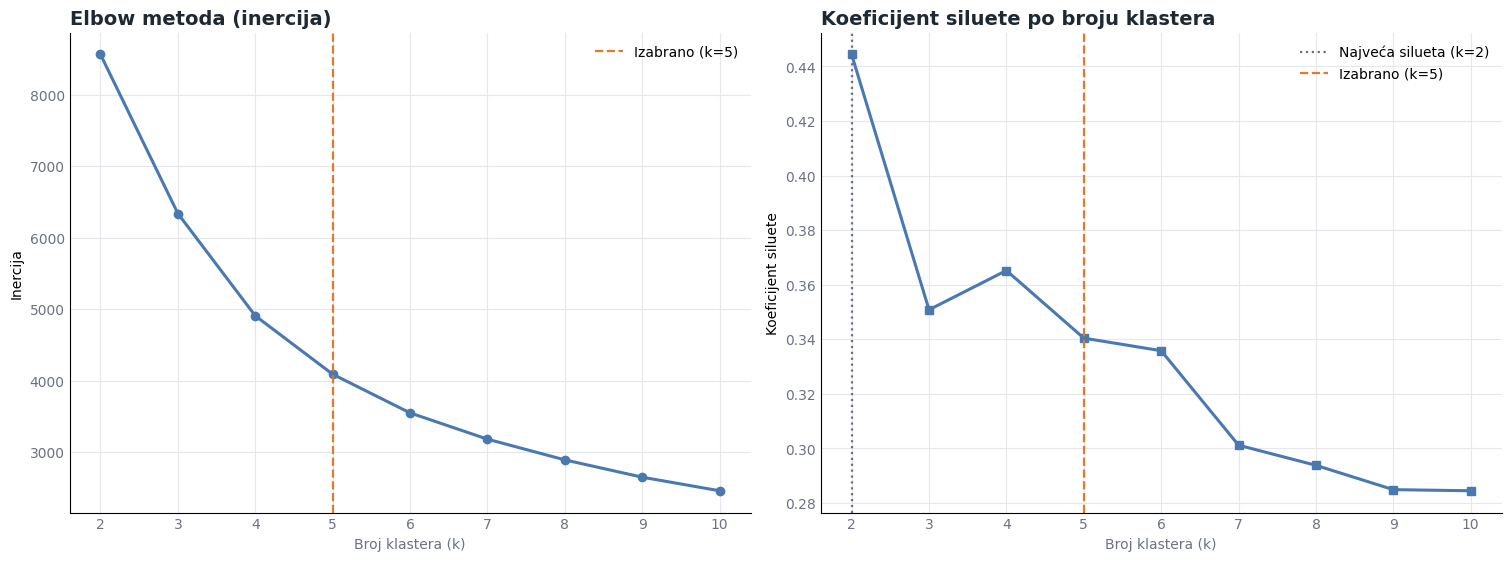

In [5]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"

k_chosen = 5
k_max_silueta = list(k_range)[int(np.argmax(silhouettes))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

ax1.plot(k_range, inertias, marker="o", color=BASE, linewidth=2.2, markersize=6)
ax1.axvline(k_chosen, color=ACCENT, linestyle="--", linewidth=1.6,
            label=f"Izabrano (k={k_chosen})")
ax1.set_title("Elbow metoda (inercija)", loc="left", fontsize=14, fontweight="bold", color=INK)
ax1.set_ylabel("Inercija")

ax2.plot(k_range, silhouettes, marker="s", color=BASE, linewidth=2.2, markersize=6)
ax2.axvline(k_max_silueta, color=MUTED, linestyle=":", linewidth=1.6,
            label=f"Najveća silueta (k={k_max_silueta})")
ax2.axvline(k_chosen, color=ACCENT, linestyle="--", linewidth=1.6,
            label=f"Izabrano (k={k_chosen})")
ax2.set_title("Koeficijent siluete po broju klastera", loc="left",
              fontsize=14, fontweight="bold", color=INK)
ax2.set_ylabel("Koeficijent siluete")

for ax in (ax1, ax2):
    ax.set_xlabel("Broj klastera (k)", color=MUTED)
    ax.set_xticks(list(k_range))
    ax.tick_params(colors=MUTED, length=0)
    ax.set_axisbelow(True)
    ax.grid(True, color=GRID, linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False)

plt.show()

# 4.3 Klasterovanje

In [7]:
model = KMeans(n_clusters=5, random_state=42, n_init=10)
rfm["Klaster"] = model.fit_predict(x_skalirano)

cluster_map = {
    0: "Neaktivni kupci",
    1: "Lojalni kupci",
    2: "VIP kupci",
    3: "Uspavani kupci",
    4: "Povremeni kupci"
}
rfm["KlasterIme"] = rfm["Klaster"].map(cluster_map)

profil = rfm.groupby("KlasterIme").agg(
    Kupaca=("CustomerID", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Prihod=("Monetary", "sum"))

profil["% kupaca"] = (profil["Kupaca"] / profil["Kupaca"].sum() * 100).round(1)
profil["% prihoda"] = (profil["Prihod"] / profil["Prihod"].sum() * 100).round(1)

print("Profil K-Means klastera:")
print(profil.round(1).sort_values("% prihoda", ascending=False))

Profil K-Means klastera:
                 Kupaca  Recency  Frequency  Monetary     Prihod  % kupaca  \
KlasterIme                                                                   
VIP kupci           454     17.3       32.6   20635.5  9368515.7       7.8   
Lojalni kupci      1284     48.8        9.1    3627.2  4657379.3      21.9   
Uspavani kupci     1352    288.7        3.8    1375.0  1858990.0      23.1   
Povremeni kupci    1141     32.5        2.5     666.2   760120.4      19.5   
Neaktivni kupci    1621    415.6        1.2     261.3   423577.3      27.7   

                 % prihoda  
KlasterIme                  
VIP kupci             54.9  
Lojalni kupci         27.3  
Uspavani kupci        10.9  
Povremeni kupci        4.5  
Neaktivni kupci        2.5  


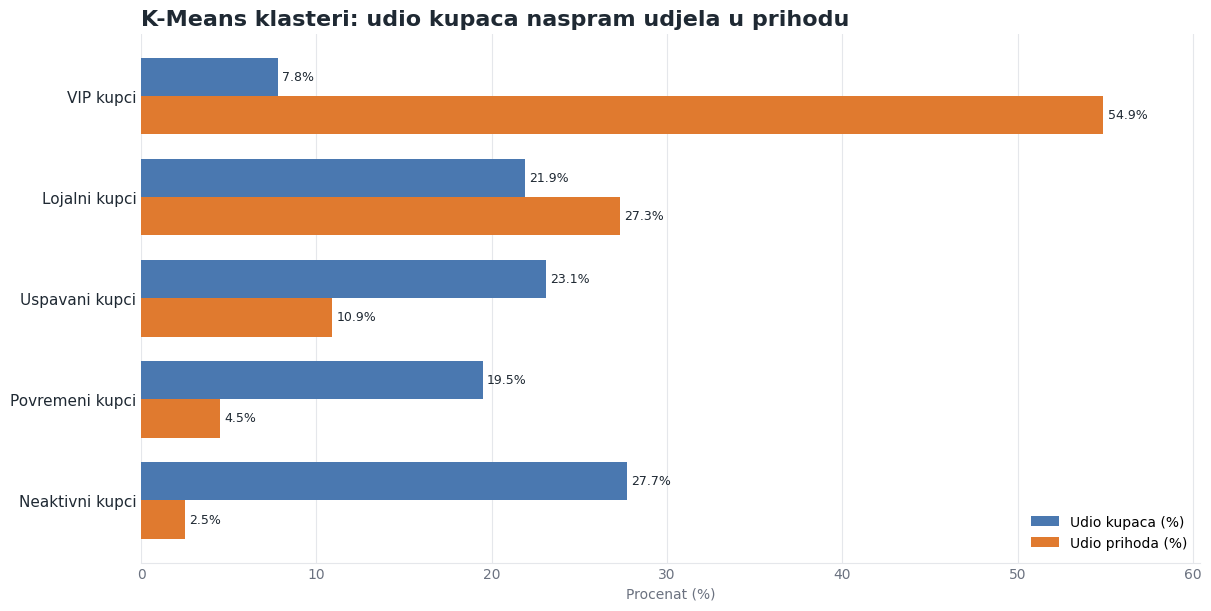

In [8]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"


def plot_customer_vs_revenue_share(df_plot, customers_col, revenue_col, title):
    data = df_plot.sort_values(revenue_col, ascending=True)

    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    y = np.arange(len(data))
    height = 0.38

    customer_bars = ax.barh(y + height / 2, data[customers_col], height=height,
                            label="Udio kupaca (%)", color=BASE)
    revenue_bars = ax.barh(y - height / 2, data[revenue_col], height=height,
                           label="Udio prihoda (%)", color=ACCENT)

    ax.bar_label(customer_bars, fmt="%.1f%%", padding=3, fontsize=9, color=INK)
    ax.bar_label(revenue_bars, fmt="%.1f%%", padding=3, fontsize=9, color=INK)

    ax.set_yticks(y)
    ax.set_yticklabels(data.index, fontsize=11, color=INK)
    ax.set_xlabel("Procenat (%)", color=MUTED)
    ax.set_title(title, loc="left", fontsize=16, fontweight="bold", color=INK)
    ax.margins(x=0.1)

    ax.tick_params(axis="x", colors=MUTED, length=0)
    ax.tick_params(axis="y", length=0)
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

    ax.legend(frameon=False, loc="lower right")
    plt.show()


plot_customer_vs_revenue_share(
    profil, "% kupaca", "% prihoda",
    "K-Means klasteri: udio kupaca naspram udjela u prihodu"
)

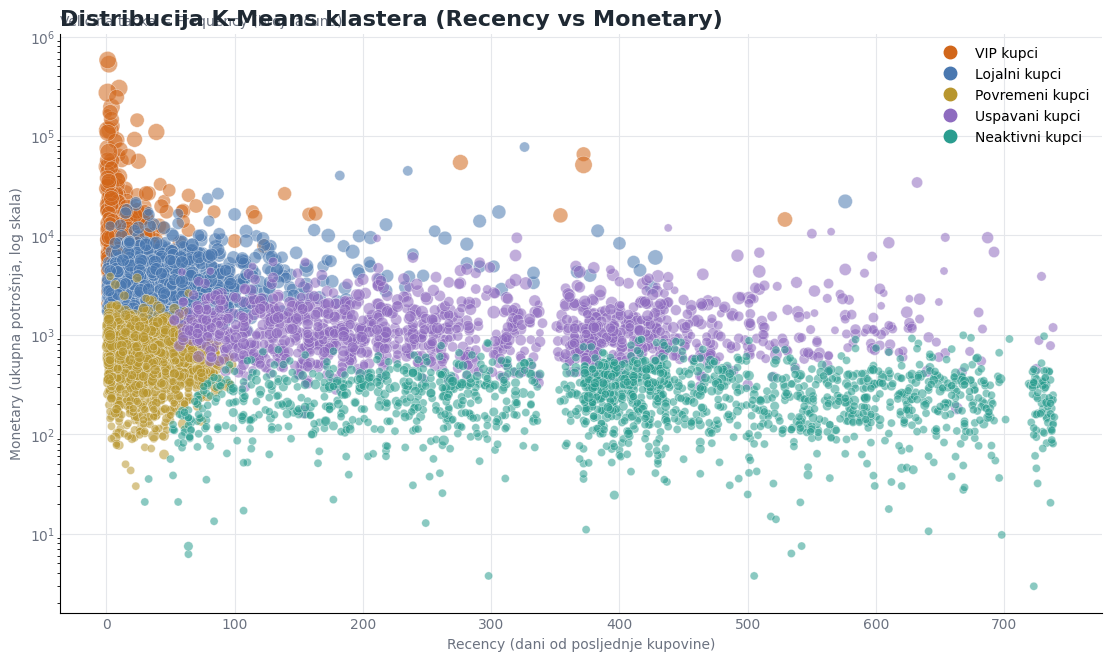

In [9]:
from matplotlib.lines import Line2D

INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"

colors = {
    "VIP kupci":       "#d1661a",
    "Lojalni kupci":   "#4a78b0",
    "Povremeni kupci": "#b8962e",
    "Uspavani kupci":  "#8e6bbf",
    "Neaktivni kupci": "#2a9d8f",
}

freq = rfm["Frequency"]
sizes = 15 + 165 * np.log1p(freq) / np.log1p(freq.max())

fig, ax = plt.subplots(figsize=(11, 6.5), constrained_layout=True)

for name, color in colors.items():
    mask = rfm["KlasterIme"] == name
    ax.scatter(rfm.loc[mask, "Recency"], rfm.loc[mask, "Monetary"],
               s=sizes[mask], color=color, alpha=0.55,
               edgecolors="white", linewidths=0.4)

ax.set_yscale("log")
ax.set_xlabel("Recency (dani od posljednje kupovine)", color=MUTED)
ax.set_ylabel("Monetary (ukupna potrošnja, log skala)", color=MUTED)
ax.set_title("Distribucija K-Means klastera (Recency vs Monetary)",
             loc="left", fontsize=16, fontweight="bold", color=INK)
ax.text(0, 1.015, "Veličina tačke = Frequency (broj računa)",
        transform=ax.transAxes, fontsize=10, color=MUTED)

ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

handles = [Line2D([], [], marker="o", linestyle="", color=c, markersize=9, label=n)
           for n, c in colors.items()]
ax.legend(handles=handles, frameon=False, loc="upper right")

plt.show()

In [10]:
crosstab = pd.crosstab(rfm["Segment"], rfm["KlasterIme"])
print("Unakrsna raspodela kupaca (RFM segmenti vs K-Means klasteri):\n")
print(crosstab)

Unakrsna raspodela kupaca (RFM segmenti vs K-Means klasteri):

KlasterIme              Lojalni kupci  Neaktivni kupci  Povremeni kupci  \
Segment                                                                   
Izgubljeni                          0             1295                0   
Lojalni                           805                1               77   
Ne smijemo ih izgubiti             33                0                0   
Novi kupci                          0                0               51   
Obećavajući                         0                7              109   
Potencijalno lojalni               42                5              661   
Treba im pažnja                     7               19               49   
U riziku                            5              102                0   
Uspavani                            0              192              118   
Šampioni                          392                0               76   

KlasterIme              Uspavani kup

In [11]:
rfm.to_parquet("../data/rfm_klasteri.parquet", index=False)

# Odgovori na pitanja — Dan 4

### Pitanje 4.1: Asimetrija pre i posle log transformacije. Zašto su oba koraka obavezna i šta bi se desilo bez standardizacije?
- **Asimetrija (skewness) pre log transformacije:** Recency ~1,23, Frequency ~19,41, Monetary ~25,23.
- **Asimetrija posle `log1p`:** Recency ~-0,51, Frequency ~0,42, Monetary ~0,34.
Oba koraka su neophodna jer K-Means pretpostavlja približno sferične klastere i koristi Euklidsko rastojanje.
- **Log transformacija** kompresuje dugačke desne repove i dovodi raspodele u simetričnu formu.
- **Standardizacija (`StandardScaler`)** dovodi sve promenljive na istu skalu (srednja vrednost 0, varijansa 1).
**Šta bi se desilo bez standardizacije?** Monetary vrednosti (koje se mere u hiljadama i desetinama hiljada) apsolutno bi dominirale Euklidskim rastojanjem u odnosu na Recency (stotine) i Frequency (desetine). Klasteri bi se formirali isključivo na osnovu potrošenog novca, dok bi frekvencija i svežina bile potpuno ignorisane.

### 1. Silueta kaže k=2, elbow kaže k=5. Koji biste izabrali i zašto?
Izabrao bih **k=5**. 
Matematički, silueta skor favorizuje k=2 (~0,44) jer deli podatke na grubu podelu „aktivni protiv neaktivnih“. Međutim, sa poslovnog aspekta, dva klastera su previše sirova i neupotrebljiva za diferencirane marketinške kampanje. 
Izbor **k=5** (koji sugeriše prelom na lakat krivoj) pruža optimalnu poslovnu granularnost jer razlikuje: VIP elitu, stabilne lojalne klijente, povremene kupce, uspavane i neaktivne kupce, omogućavajući targetirane i profitabilne akcije za svaki segment.

### 2. Opišite svaki klaster u jednoj rečenici razumljivoj direktoru prodaje.
1. **VIP kupci (Klaster 2):** Naša najvrednija grupa od 454 kupca (7,8% baze) koja kupuje na svakih 17 dana i sama generiše skoro 55% celokupnog prihoda firme.
2. **Lojalni kupci (Klaster 1):** Stabilan oslonac od 1.284 stalna kupca koji naručuju svakih 45 dana i donose preko 27% ukupnog prihoda.
3. **Povremeni kupci (Klaster 4):** Grupa od 1.141 novijeg/manjeg kupca sa svežom kupovinom pre mesec dana, ali sa skromnijim korpama (4,5% prihoda).
4. **Uspavani kupci (Klaster 3):** Nekadašnji umereni kupci (1.352 klijenta) koji nisu naručivali oko 9 meseci i čine 10,9% prihoda.
5. **Neaktivni kupci (Klaster 0):** Baza od 1.621 kupca koji nisu aktivni više od godinu dana i donose zanemarljivih 2,5% prihoda.

### 3. Da li se K-Means i RFM segmenti poklapaju? Gde se najviše razilaze?
Postoji **visoko poklapanje na ekstremima**: K-Means VIP klaster se ubedljivo preklapa sa RFM „Šampionima“, a klaster neaktivnih kupaca sa RFM „Izgubljenima“.
Najviše se razilaze u **srednjim prelaznim segmentima** (umerena monetarnost i frekvencija). RFM koristi veštačke, fiksne granice po kvintilima (seče ravnomerno po 20%), dok K-Means pronalazi prirodne gustine tačaka u 3D prostoru, pa spaja delove RFM segmenata poput „Potencijalno lojalnih“ i „U riziku“ prema njihovim stvarnim Euklidskim udaljenostima.

### 4. Koji pristup biste koristili u praksi i za šta? Prednost svakog.
U praksi je najbolje koristiti **oba pristupa komplementarno**:
- **Prednost RFM-a:** Potpuna razumljivost i transparentnost — jednostavan je za objašnjenje prodavcima, automatizaciju u CRM sistemu i kreiranje direktnih fiksnih pravila (npr. popust ako je R>=4 i F>=4).
- **Prednost K-Means-a:** Objektivno grupisanje bez pretpostavljenih pravila — algoritam sam detektuje prirodnu strukturu baze i stvarne granice među kupcima, što je idealno za periodično strateško preispitivanje segmenata.
